# 09 Supplemental Outward-FDI Source Comparison

## Purpose

This notebook tests whether the supplemental **Outward Direct Investment** workbook can extend or supplement the IMF Direct Investment Positions (DIP) series used for the US–China Closeness Index.

The notebook answers one narrow methodological question:

> Are the country-year outward-FDI positions in the supplemental workbook sufficiently comparable with the closest like-for-like IMF DIP observations to be used in the production indicator?

The comparison is deliberately completed **before** any FDI closeness score is designed. Similar labels are not treated as proof that two series measure the same statistical object.

## Decision standard

The comparison uses the closest like-for-like IMF DIP series:

- anchor-reported perspective;
- anchor-to-country economic direction;
- reported official data;
- outward direct-investment position;
- all financial instruments;
- all entities;
- net assets less liabilities;
- US dollars, converted by the source extract to USD millions.

A source is not accepted merely because its aggregate correlation is high. The review also considers country-level alignment, sign agreement, proportional differences, extreme exceptions and evidence of displaced workbook columns.

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)


def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root without embedding a personal absolute path."""
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the project repository.")


def find_unique_file(root: Path, filename: str) -> Path:
    """Locate one exact repository file and fail if the placement is ambiguous."""
    matches = [p for p in root.rglob(filename) if ".git" not in p.parts and ".venv" not in p.parts]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one {filename!r}; found {len(matches)}: {matches}")
    return matches[0]


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMF_PATH = find_unique_file(PROJECT_ROOT, "imf_dip_primary_candidates.csv")
SUPPLEMENTAL_PATH = find_unique_file(PROJECT_ROOT, "outward_fdi_stock_long.csv")

print(f"Project root: {PROJECT_ROOT.relative_to(PROJECT_ROOT)}")
print(f"IMF input: {IMF_PATH.relative_to(PROJECT_ROOT)}")
print(f"Supplemental input: {SUPPLEMENTAL_PATH.relative_to(PROJECT_ROOT)}")
print(f"Output directory: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Project root: .
IMF input: data/interim/fdi/imf_dip_primary_candidates.csv
Supplemental input: outputs/tables/fdi_national_sources/outward_fdi_stock_long.csv
Output directory: outputs/tables


## 1. Load and validate the two extracts

The notebook fails early if required fields are absent. This prevents a changed upstream schema from silently altering the comparison.

In [2]:
imf = pd.read_csv(IMF_PATH)
supplemental = pd.read_csv(SUPPLEMENTAL_PATH)

required_imf = {
    "country_source_name", "anchor", "reporting_perspective", "economic_direction",
    "DV_TYPE", "DI_DIRECTION", "INSTR_ASSET", "DI_ENTITY", "ACCOUNTING_ENTRY",
    "UNIT", "year", "fdi_position_usd_millions", "observed"
}
required_supplemental = {
    "block", "country_source_name", "unit", "name_classification", "year",
    "value", "observed", "negative", "zero"
}

assert required_imf.issubset(imf.columns), sorted(required_imf - set(imf.columns))
assert required_supplemental.issubset(supplemental.columns), sorted(required_supplemental - set(supplemental.columns))

print(f"IMF candidate rows: {len(imf):,}")
print(f"Supplemental long-form rows: {len(supplemental):,}")

IMF candidate rows: 48,192
Supplemental long-form rows: 26,001


## 2. Select the comparison series

This is a **source-comparability** exercise, not the later production-selection hierarchy. Accordingly, the IMF side is restricted to official outward positions reported by the anchor itself. Counterparty-derived observations are not mixed into the benchmark.

In [3]:
imf_comparison = imf.loc[
    (imf["reporting_perspective"] == "anchor_report")
    & (imf["economic_direction"] == "anchor_to_country")
    & (imf["DV_TYPE"] == "Reported official data")
    & (imf["DI_DIRECTION"] == "Outward")
    & (imf["INSTR_ASSET"] == "All financial instruments")
    & (imf["DI_ENTITY"] == "All entities")
    & (imf["ACCOUNTING_ENTRY"] == "Net (assets less liabilities)")
    & imf["observed"]
].copy()

supplemental_comparison = supplemental.loc[
    supplemental["block"].isin(["china_odi_stock", "us_odi_stock"])
    & (supplemental["name_classification"] == "economy_candidate")
    & supplemental["observed"]
].copy()

supplemental_comparison["anchor"] = supplemental_comparison["block"].map({
    "china_odi_stock": "China",
    "us_odi_stock": "United States",
})

imf_key = ["anchor", "country_source_name", "year"]
assert not imf_comparison.duplicated(imf_key).any(), "Duplicate IMF comparison keys found."

print(f"Observed IMF benchmark rows: {len(imf_comparison):,}")
print(f"Observed supplemental economy rows: {len(supplemental_comparison):,}")
print(f"IMF years: {imf_comparison['year'].min()}–{imf_comparison['year'].max()}")

Observed IMF benchmark rows: 4,908
Observed supplemental economy rows: 8,904
IMF years: 2009–2024


## 3. Reconcile source economy names

The crosswalk is intentionally conservative:

1. reviewed manual aliases;
2. exact matches after punctuation and common legal-form normalisation;
3. otherwise unmatched.

No automatic fuzzy match is accepted. Four obvious abbreviated names are included in the reviewed alias dictionary rather than being accepted algorithmically.

In [4]:
def normalise_name(value: object) -> str:
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode().lower()
    text = text.replace("&", " and ")
    text = re.sub(
        r"\b(the|republic of|people's republic of|islamic republic of|democratic republic of|plurinational state of|bolivarian republic of)\b",
        " ", text,
    )
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text).split())


reviewed_aliases = {
    "Bahamas": "Bahamas, The",
    "Bolivia": "Bolivia, Plurinational State of",
    "Brunei": "Brunei Darussalam",
    "Cape Verde": "Cabo Verde",
    "Congo, Dem. Rep.": "Congo, Democratic Republic of the",
    "Congo, Rep.": "Congo, Republic of",
    "Czech Republic": "Czechia",
    "Egypt": "Egypt, Arab Republic of",
    "Gambia": "Gambia, The",
    "Iran": "Iran, Islamic Republic of",
    "Laos": "Lao People's Democratic Republic",
    "Macedonia": "North Macedonia",
    "Micronesia": "Micronesia, Federated States of",
    "Micronesia (Fed. States of)": "Micronesia, Federated States of",
    "Moldova": "Moldova, Republic of",
    "Russia": "Russian Federation",
    "Saint Kitts & Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",
    "Saint Vincent & The Grenadines": "St. Vincent and the Grenadines",
    "South Korea": "Korea, Republic of",
    "Syria": "Syrian Arab Republic",
    "Taiwan": "Taiwan Province of China",
    "Tanzania": "Tanzania, United Republic of",
    "Turkey": "Turkiye",
    "Venezuela": "Venezuela, Republica Bolivariana de",
    "Yemen": "Yemen, Republic of",
}

imf_names = sorted(imf_comparison["country_source_name"].dropna().unique())
imf_by_normalised = {normalise_name(name): name for name in imf_names}

crosswalk_rows = []
for supplemental_name in sorted(supplemental_comparison["country_source_name"].dropna().unique()):
    if supplemental_name in reviewed_aliases and reviewed_aliases[supplemental_name] in imf_names:
        imf_name = reviewed_aliases[supplemental_name]
        method = "reviewed_alias"
    else:
        imf_name = imf_by_normalised.get(normalise_name(supplemental_name))
        method = "normalised_exact" if imf_name else "unmatched"
    crosswalk_rows.append({
        "supplemental_name": supplemental_name,
        "imf_name": imf_name,
        "match_method": method,
    })

name_crosswalk = pd.DataFrame(crosswalk_rows)
name_crosswalk["match_method"].value_counts(dropna=False)

match_method
normalised_exact    168
unmatched            35
reviewed_alias       18
Name: count, dtype: int64

In [5]:
unmatched_names = name_crosswalk.loc[name_crosswalk["imf_name"].isna()].copy()
print(f"Unmatched supplemental names: {len(unmatched_names)}")
unmatched_names.head(40)

Unmatched supplemental names: 35


,supplemental_name,imf_name,match_method
3,Andorra,None,unmatched
5,Anguilla,None,unmatched
6,"Anguilla, British",None,unmatched
10,Aruba,None,unmatched
15,Bahrain,None,unmatched
42,Comoros,None,unmatched
44,Congo (Democratic Republic),None,unmatched
49,Curaçao,None,unmatched
60,Eritrea,None,unmatched
62,Eswatini,None,unmatched


## 4. Construct the matched overlap panel

Differences are calculated in USD millions. The symmetric percentage difference is bounded between 0 and 200 and treats the two sources symmetrically:

\[
\operatorname{SPD}(x,y)=

rac{200|x-y|}{|x|+|y|}.
\]

A zero denominator is left undefined rather than presented as agreement.

In [6]:
supplemental_mapped = supplemental_comparison.merge(
    name_crosswalk,
    left_on="country_source_name",
    right_on="supplemental_name",
    how="left",
    validate="many_to_one",
)

imf_values = imf_comparison[[
    "anchor", "country_source_name", "year", "fdi_position_usd_millions"
]].rename(columns={
    "country_source_name": "imf_name",
    "fdi_position_usd_millions": "imf_value_usd_mn",
})

overlap = supplemental_mapped.loc[supplemental_mapped["imf_name"].notna()].merge(
    imf_values,
    on=["anchor", "imf_name", "year"],
    how="inner",
    validate="many_to_one",
).rename(columns={
    "country_source_name": "supplemental_name_original",
    "value": "supplemental_value_usd_mn",
})

duplicate_key = ["anchor", "imf_name", "year"]
duplicate_rows = overlap.loc[overlap.duplicated(duplicate_key, keep=False)].copy()
if not duplicate_rows.empty:
    consistency = duplicate_rows.groupby(duplicate_key)["supplemental_value_usd_mn"].nunique(dropna=False)
    assert consistency.le(1).all(), "Conflicting duplicate supplemental values found."
    overlap = overlap.drop_duplicates(duplicate_key, keep="first").copy()

print(f"Duplicate supplemental rows removed after confirming identical values: {len(duplicate_rows) // 2}")

overlap["difference_usd_mn"] = overlap["supplemental_value_usd_mn"] - overlap["imf_value_usd_mn"]
overlap["absolute_difference_usd_mn"] = overlap["difference_usd_mn"].abs()
overlap["same_sign"] = np.sign(overlap["supplemental_value_usd_mn"]) == np.sign(overlap["imf_value_usd_mn"])
denominator = overlap["supplemental_value_usd_mn"].abs() + overlap["imf_value_usd_mn"].abs()
overlap["symmetric_percentage_difference"] = np.where(
    denominator > 0,
    200 * overlap["absolute_difference_usd_mn"] / denominator,
    np.nan,
)
overlap["supplemental_to_imf_ratio"] = overlap["supplemental_value_usd_mn"] / overlap["imf_value_usd_mn"].replace(0, np.nan)
overlap["exact_match"] = np.isclose(overlap["supplemental_value_usd_mn"], overlap["imf_value_usd_mn"], rtol=0, atol=1e-9)

overlap.groupby("anchor").agg(
    matched_rows=("year", "size"),
    matched_economies=("imf_name", "nunique"),
    first_year=("year", "min"),
    last_year=("year", "max"),
)

Duplicate supplemental rows removed after confirming identical values: 48


,matched_rows,matched_economies,first_year,last_year
anchor,,,,
China,1141,163,2018,2024
United States,2248,178,2009,2024


## 5. Overall and subperiod diagnostics

In [7]:
def safe_corr(frame: pd.DataFrame, method: str) -> float:
    pair = frame[["supplemental_value_usd_mn", "imf_value_usd_mn"]].dropna()
    if len(pair) < 3 or pair.nunique().min() < 2:
        return np.nan
    return pair.iloc[:, 0].corr(pair.iloc[:, 1], method=method)


def summarise(frame: pd.DataFrame, anchor: str, period: str, scope: str) -> dict:
    positive = frame.loc[(frame["supplemental_value_usd_mn"] > 0) & (frame["imf_value_usd_mn"] > 0)]
    return {
        "anchor": anchor,
        "period": period,
        "scope": scope,
        "matched_rows": len(frame),
        "matched_economies": frame["imf_name"].nunique(),
        "pearson_levels": safe_corr(frame, "pearson"),
        "spearman_levels": safe_corr(frame, "spearman"),
        "median_symmetric_percentage_difference": frame["symmetric_percentage_difference"].median(),
        "p75_symmetric_percentage_difference": frame["symmetric_percentage_difference"].quantile(0.75),
        "sign_agreement_pct": 100 * frame["same_sign"].mean() if len(frame) else np.nan,
        "exact_match_pct": 100 * frame["exact_match"].mean() if len(frame) else np.nan,
        "within_10pct_spd_pct": 100 * frame["symmetric_percentage_difference"].le(10).mean() if len(frame) else np.nan,
        "over_100pct_spd_pct": 100 * frame["symmetric_percentage_difference"].gt(100).mean() if len(frame) else np.nan,
        "median_positive_ratio": positive["supplemental_to_imf_ratio"].median(),
        "aggregate_ratio": frame["supplemental_value_usd_mn"].sum() / frame["imf_value_usd_mn"].sum()
            if frame["imf_value_usd_mn"].sum() != 0 else np.nan,
    }

summary_rows = []
for anchor, group in overlap.groupby("anchor"):
    summary_rows.append(summarise(group, anchor, "2009–2024", "all matched observations"))
    material = group.loc[
        (group["supplemental_value_usd_mn"].abs() >= 10)
        & (group["imf_value_usd_mn"].abs() >= 10)
    ]
    summary_rows.append(summarise(material, anchor, "2009–2024", "both absolute values ≥ USD 10mn"))
    for start, end in [(2009, 2014), (2015, 2019), (2020, 2024)]:
        subperiod = group.loc[group["year"].between(start, end)]
        summary_rows.append(summarise(subperiod, anchor, f"{start}–{end}", "all matched observations"))

comparison_summary = pd.DataFrame(summary_rows)
comparison_summary

,anchor,period,scope,matched_rows,matched_economies,pearson_levels,spearman_levels,median_symmetric_percentage_difference,p75_symmetric_percentage_difference,sign_agreement_pct,exact_match_pct,within_10pct_spd_pct,over_100pct_spd_pct,median_positive_ratio,aggregate_ratio
0,China,2009–2024,all matched observations,1141,163,0.006574,0.630055,5.661588,148.227945,98.510079,1.402279,51.533742,31.551271,1.000004,2.470552
1,China,2009–2024,both absolute values ≥ USD 10mn,948,147,0.000022,0.577357,0.012571,102.497273,100.000000,0.632911,56.856540,25.316456,1.000002,2.462627
2,China,2009–2014,all matched observations,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,China,2015–2019,all matched observations,326,163,-0.001888,0.609601,72.709887,159.879677,97.546012,0.613497,15.644172,40.797546,1.654569,2.533993
4,China,2020–2024,all matched observations,815,163,0.007785,0.640939,0.002243,141.208546,98.895706,1.717791,65.889571,27.852761,1.000000,2.452495
5,United States,2009–2024,all matched observations,2248,178,0.999305,0.965067,0.000000,0.000000,99.065836,89.813167,87.144128,2.357651,1.000000,1.007855
6,United States,2009–2024,both absolute values ≥ USD 10mn,1795,144,0.999700,0.981222,0.000000,0.000000,99.777159,88.690808,95.264624,1.559889,1.000000,1.002578
7,United States,2009–2014,all matched observations,798,167,0.998485,0.950429,0.000000,0.000000,98.245614,98.120301,94.736842,1.879699,1.000000,1.013577
8,United States,2015–2019,all matched observations,742,165,0.999541,0.976418,0.000000,0.000000,100.000000,97.978437,87.466307,1.886792,1.000000,1.007264
9,United States,2020–2024,all matched observations,708,153,0.999508,0.972036,0.000000,1.987054,99.011299,71.892655,78.248588,3.389831,1.000000,1.003771


## 6. Annual stability

In [8]:
annual_rows = []
for (anchor, year), group in overlap.groupby(["anchor", "year"]):
    row = summarise(group, anchor, str(year), "annual")
    annual_rows.append(row)

comparison_by_year = pd.DataFrame(annual_rows)
comparison_by_year[[
    "anchor", "period", "matched_rows", "pearson_levels", "spearman_levels",
    "median_symmetric_percentage_difference", "aggregate_ratio", "sign_agreement_pct"
]].head(10)

,anchor,period,matched_rows,pearson_levels,spearman_levels,median_symmetric_percentage_difference,aggregate_ratio,sign_agreement_pct
0,China,2018,163,-0.001464,0.601351,70.516752,2.542345,98.159509
1,China,2019,163,-0.002296,0.617058,78.477426,2.526110,96.932515
2,China,2020,163,-0.007668,0.645687,0.002046,2.048068,98.159509
3,China,2021,163,-0.001238,0.634609,0.001372,2.871068,99.386503
4,China,2022,163,0.010528,0.612577,0.002856,2.597305,99.386503
5,China,2023,163,0.019744,0.634065,0.002830,2.508662,99.386503
6,China,2024,163,0.038686,0.668782,0.002714,2.360255,98.159509
7,United States,2009,127,0.998655,0.948360,0.000000,1.012035,98.425197
8,United States,2010,130,0.998068,0.950837,0.000000,1.014586,98.461538
9,United States,2011,127,0.998264,0.953236,0.000000,1.014075,98.425197


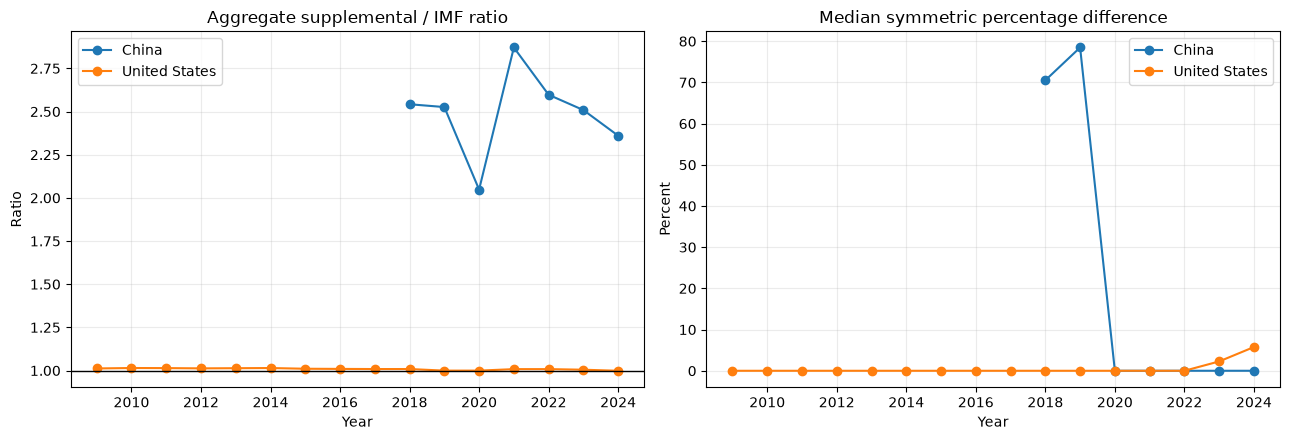

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for anchor, group in comparison_by_year.groupby("anchor"):
    axes[0].plot(group["period"].astype(int), group["aggregate_ratio"], marker="o", label=anchor)
    axes[1].plot(group["period"].astype(int), group["median_symmetric_percentage_difference"], marker="o", label=anchor)

axes[0].axhline(1, color="black", linewidth=1)
axes[0].set(title="Aggregate supplemental / IMF ratio", xlabel="Year", ylabel="Ratio")
axes[1].set(title="Median symmetric percentage difference", xlabel="Year", ylabel="Percent")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Country-level persistence and extreme exceptions

A strong aggregate relationship can conceal mislabelled country columns. The next diagnostics therefore examine repeated country-level disagreement and the largest absolute discrepancies.

In [10]:
def safe_median(series: pd.Series) -> float:
    values = series.replace([np.inf, -np.inf], np.nan).dropna()
    return values.median() if not values.empty else np.nan


country_rows = []
for (anchor, imf_name), group in overlap.groupby(["anchor", "imf_name"]):
    if len(group) < 5:
        continue
    country_rows.append({
        "anchor": anchor,
        "imf_name": imf_name,
        "supplemental_name": group["supplemental_name_original"].iloc[0],
        "matched_years": len(group),
        "median_symmetric_percentage_difference": safe_median(group["symmetric_percentage_difference"]),
        "median_ratio": safe_median(group["supplemental_to_imf_ratio"]),
        "sign_agreement_pct": 100 * group["same_sign"].mean(),
        "time_series_pearson": safe_corr(group, "pearson"),
    })

comparison_by_country = pd.DataFrame(country_rows).sort_values(
    ["anchor", "median_symmetric_percentage_difference"],
    ascending=[True, False],
)

comparison_by_country.groupby("anchor", group_keys=False).head(12)

,anchor,imf_name,supplemental_name,matched_years,median_symmetric_percentage_difference,median_ratio,sign_agreement_pct,time_series_pearson
47,China,El Salvador,El Salvador,7,200.000000,NaN,0.000000,NaN
154,China,Ukraine,Ukraine,7,199.937853,6435.358470,100.000000,0.706098
150,China,Trinidad and Tobago,Trinidad & Tobago,7,199.867895,3026.905413,100.000000,-0.953574
18,China,Bolivia,Bolivia,7,199.565042,918.628838,100.000000,-0.079578
30,China,Cayman Islands,Cayman Islands,7,199.527395,0.001183,100.000000,0.059347
45,China,Ecuador,Ecuador,7,199.493058,0.001269,100.000000,0.602652
156,China,United Kingdom,United Kingdom,7,199.466700,0.001335,100.000000,0.504249
64,China,Honduras,Honduras,7,199.452365,729.413243,100.000000,-0.071856
107,China,"Netherlands, The",Netherlands,7,199.198948,0.002007,100.000000,-0.842195
157,China,Uruguay,Uruguay,7,199.132364,460.022959,100.000000,0.780765


In [11]:
exceptions = overlap.loc[
    (overlap["symmetric_percentage_difference"] > 100)
    | (overlap["absolute_difference_usd_mn"] >= 25_000)
    | (~overlap["same_sign"])
].copy()

exceptions = exceptions[[
    "anchor", "year", "imf_name", "supplemental_name_original",
    "imf_value_usd_mn", "supplemental_value_usd_mn", "difference_usd_mn",
    "absolute_difference_usd_mn", "symmetric_percentage_difference",
    "supplemental_to_imf_ratio", "same_sign", "match_method"
]].sort_values(["anchor", "absolute_difference_usd_mn"], ascending=[True, False])

exceptions.groupby("anchor", group_keys=False).head(15)

,anchor,year,imf_name,supplemental_name_original,imf_value_usd_mn,supplemental_value_usd_mn,difference_usd_mn,absolute_difference_usd_mn,symmetric_percentage_difference,supplemental_to_imf_ratio,same_sign,match_method
850,China,2021,Ukraine,Ukraine,136.932800,693740.17,693603.237200,693603.237200,199.921062,5066.281928,True,normalised_exact
849,China,2020,Ukraine,Ukraine,190.344700,629810.25,629619.905300,629619.905300,199.879146,3308.787952,True,normalised_exact
852,China,2023,Ukraine,Ukraine,96.538300,600800.97,600704.431700,600704.431700,199.935737,6223.446756,True,normalised_exact
851,China,2022,Ukraine,Ukraine,80.361900,596152.91,596072.548100,596072.548100,199.946087,7418.352602,True,normalised_exact
853,China,2024,Ukraine,Ukraine,86.412100,567713.10,567626.687900,567626.687900,199.939125,6569.833391,True,normalised_exact
898,China,2020,Bolivia,Bolivia,287.962800,457026.99,456739.027200,456739.027200,199.748127,1587.104272,True,normalised_exact
912,China,2020,Cayman Islands,Cayman Islands,457026.989641,428.51,-456598.479641,456598.479641,199.625310,0.000938,True,normalised_exact
1067,China,2021,Trinidad and Tobago,Trinidad & Tobago,112.512700,447477.34,447364.827300,447364.827300,199.899450,3977.127382,True,normalised_exact
848,China,2019,Ukraine,Ukraine,65.905700,436046.97,435981.064300,435981.064300,199.939552,6616.225455,True,normalised_exact
847,China,2018,Ukraine,Ukraine,63.208900,406771.93,406708.721100,406708.721100,199.937853,6435.358470,True,normalised_exact


## 8. Interpretation

### United States

The US overlap is expected to show near-unit aggregate ratios, very high level and rank correlations, and a large share of exact matches. This supports the interpretation that the supplemental US block largely reproduces the same underlying official position data as IMF DIP. Local exceptions, such as a displaced or mislabelled country column, must still be excluded before any historical extension.

### China

The China overlap contains many matching or near-matching observations, but also very large country-level discrepancies. Repeated cases in which a plausible offshore-centre value appears under an unrelated economy are evidence of workbook-column displacement or header misalignment. That is a data-integrity problem, not a difference that can be fixed with a global scale factor.

### Methodological decision

- Retain IMF DIP as the production FDI source from 2009 onward.
- Do not use the current supplemental China extract for scoring or historical extension.
- Treat the supplemental US block as a possible future pre-2009 extension only after a separate exception-filtering and provenance step.
- Do not use the workbook's precomputed US-minus-China block.
- Do not calculate the FDI closeness score in this notebook. That belongs in the next production-development notebook.

## 9. Export selected audit tables

Only compact tables needed for review and reproducibility are written to `outputs/tables`. The full overlap panel remains an in-memory development object to avoid adding an unnecessary large duplicate to the repository.

In [12]:
exports = {
    "fdi_source_comparison_summary.csv": comparison_summary,
    "fdi_source_comparison_by_year.csv": comparison_by_year,
    "fdi_source_comparison_by_country.csv": comparison_by_country,
    "fdi_source_overlap_exceptions.csv": exceptions,
}

for filename, frame in exports.items():
    path = OUTPUT_DIR / filename
    frame.to_csv(path, index=False)
    print(f"Wrote {path.relative_to(PROJECT_ROOT)} ({len(frame):,} rows)")

Wrote outputs/tables/fdi_source_comparison_summary.csv (10 rows)
Wrote outputs/tables/fdi_source_comparison_by_year.csv (23 rows)
Wrote outputs/tables/fdi_source_comparison_by_country.csv (329 rows)
Wrote outputs/tables/fdi_source_overlap_exceptions.csv (415 rows)


## 10. Final checks

In [13]:
assert set(overlap["anchor"].unique()) == {"China", "United States"}
assert overlap["year"].between(2009, 2024).all()
assert not overlap.duplicated(["anchor", "imf_name", "year"]).any()
assert overlap["symmetric_percentage_difference"].dropna().between(0, 200).all()
assert all((OUTPUT_DIR / filename).exists() for filename in exports)

us_row = comparison_summary.loc[
    (comparison_summary["anchor"] == "United States")
    & (comparison_summary["period"] == "2009–2024")
    & (comparison_summary["scope"] == "all matched observations")
].iloc[0]
china_row = comparison_summary.loc[
    (comparison_summary["anchor"] == "China")
    & (comparison_summary["period"] == "2009–2024")
    & (comparison_summary["scope"] == "all matched observations")
].iloc[0]

assert us_row["pearson_levels"] > 0.99
assert us_row["exact_match_pct"] > 80
assert china_row["over_100pct_spd_pct"] > 20

print("Notebook 09 checks passed.")
print("Decision: use IMF DIP for production; reject the current supplemental China extract.")

Notebook 09 checks passed.
Decision: use IMF DIP for production; reject the current supplemental China extract.
